# FSV-Net — Run All

**One notebook. Run top to bottom. Everything gets checked and drawn.**

This trains a real video deepfake detector end to end on a synthetic dataset the
notebook generates itself, so it works with **no download, no dataset request, and no
GPU**. On the RTX 4060 it takes a few minutes; on CPU, about half an hour. When your
real dataset arrives, change one cell (§2) and rerun — nothing else changes.

### What it proves, in order

| § | Question it answers | Output |
|---|---|---|
| 1 | Does the environment work? | version table |
| 2 | Which dataset am I running on? | config dump |
| 3 | **Does TSC detect what it claims to?** | Fig 1–3 — the controlled experiment |
| 4 | Are the splits honest? | Fig 4 — leakage audit |
| 5 | Did preprocessing produce sane clips? | Fig 5 — cached face crops |
| 6 | What does the model cost? | Fig 6 — parameter budget |
| 7 | Does it train? | Fig 7 — loss, val AUC, branch attention |
| 8 | How well does it do? | Fig 8 — ROC + confusion matrix |
| 9 | **Does the TSC branch earn its place?** | Fig 9 — ablation with CIs |
| 10 | What did the model rely on? | Fig 10 — branch attention |
| 11 | Can it explain itself? | Fig 11 — evidence pack + reasoning |
| 12 | Summary | Fig 12 — dashboard |

### The two claims being tested

1. **Temporal Spectral Coherence.** Real camera detail is temporally *white* (sensor
   noise is independent per frame). Generated detail is computed from a smooth latent,
   so it is temporally *coloured*. §3 builds clips whose *average spatial spectra are
   identical by construction* and only their temporal structure differs — so a
   per-frame frequency detector **must** sit at chance, and any separation TSC finds
   is genuinely temporal.
2. **Evidence-conditioned reasoning.** §11 hands a reasoning layer
   percentile-calibrated measurements rather than a bare probability.

> Section 3 is the one to read first. If it fails, the novelty claim is broken.

## 1 · Environment

In [1]:
%matplotlib inline
import sys, os, json, time, platform, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if not (ROOT / "src" / "fsvnet").exists():          # be forgiving about cwd
    for cand in [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]:
        if (cand / "src" / "fsvnet").exists():
            ROOT = cand; break
assert (ROOT / "src" / "fsvnet").exists(), (
    f"Could not find src/fsvnet from {Path.cwd()}. Run this notebook from inside "
    "the video_detector folder.")
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

import fsvnet
from fsvnet.config import Config
from fsvnet.utils import seed_everything, log, free_cuda
from fsvnet import viz
viz.use_style()

rows = [
    ("project root", str(ROOT)),
    ("fsvnet", fsvnet.__version__),
    ("python", platform.python_version()),
    ("torch", torch.__version__),
    ("CUDA available", str(torch.cuda.is_available())),
    ("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "— CPU only"),
    ("VRAM", f"{torch.cuda.get_device_properties(0).total_memory/1024**3:.1f} GB"
             if torch.cuda.is_available() else "—"),
]
display(pd.DataFrame(rows, columns=["", "value"]).style.hide(axis="index"))

,value
project root,/home/claude/build/video_detector
fsvnet,1.0.0
python,3.11.15
torch,2.13.0+cu130
CUDA available,False
GPU,— CPU only
VRAM,—


## 2 · Configuration — **the only cell you edit**

`DEMO_MODE = True` generates its own dataset and runs everything small enough to
finish quickly. Set it to `False` and fill in a dataset root to run for real.

`Config.auto_tune()` reads the card and rewrites clip length, batch size, AMP and VLM
size to fit — on your 4060 it picks 16 frames, batch 2 × accumulation 8, and
Qwen2.5-VL-3B in 4-bit. In demo mode we override those downwards so the notebook
finishes in minutes.

In [2]:
DEMO_MODE = True          # <-- False when you have Celeb-DF / FF++ on disk

cfg = Config()
cfg.auto_tune(verbose=True)
cfg.run_name = "runall_demo" if DEMO_MODE else "fsvnet_v1"
cfg.paths.mkdirs()
seed_everything(cfg.data.seed)

if DEMO_MODE:
    # small, fast, still a genuine end-to-end run
    cfg.data.num_frames = 8
    cfg.data.frame_stride = 1
    cfg.data.img_size = 112
    cfg.data.face_backend = "none"        # synthetic clips contain no faces
    cfg.data.min_faces_per_clip = 0.0
    cfg.data.clips_per_video_eval = 2
    cfg.train.epochs = 6
    cfg.train.batch_size = 4
    cfg.train.grad_accum = 2
    cfg.train.num_workers = 0             # 0 keeps Windows + notebooks happy
    cfg.train.early_stop_patience = 99
    cfg.model.freeze_spatial_epochs = 0
    ABLATION_EPOCHS = 3
else:
    # cfg.paths.celebdf_root = Path(r"D:/data/Celeb-DF-v2")
    # cfg.paths.ffpp_root    = Path(r"D:/data/FaceForensics++")
    ABLATION_EPOCHS = None                # use cfg.train.epochs

# ImageNet weights need a download; fall back cleanly if there is no network.
import urllib.request
try:
    urllib.request.urlopen("https://download.pytorch.org/", timeout=4)
    cfg.model.pretrained = True
except Exception:
    cfg.model.pretrained = False
    print("No network for torchvision weights -> training the spatial trunk from "
          "scratch. Fine for this demo; use pretrained=True on your machine.")

# Warm-start the per-frame branches from the image-level FSW-Net if it is there.
fsw = ROOT.parent / "notebooks" / "best_fsw_net.pth"
cfg.model.init_from_fswnet = str(fsw) if fsw.exists() else None

print(f"\nrun            : {cfg.run_name}   (DEMO_MODE={DEMO_MODE})")
print(f"device         : {cfg.device}")
print(f"clip           : {cfg.data.num_frames} frames @ {cfg.data.img_size}px")
print(f"batch          : {cfg.train.batch_size} x accum {cfg.train.grad_accum}"
      f"  (effective {cfg.train.batch_size * cfg.train.grad_accum})")
print(f"branches       : {cfg.active_branches()}")
print(f"FSW-Net warm start: {cfg.model.init_from_fswnet or 'not found — from scratch'}")

[config] No CUDA device. CPU safety net engaged:
         frames=8, batch=1, amp=off. Training will be slow;
         use this path to validate the pipeline, not to train.


No network for torchvision weights -> training the spatial trunk from scratch. Fine for this demo; use pretrained=True on your machine.

run            : runall_demo   (DEMO_MODE=True)
device         : cpu
clip           : 8 frames @ 112px
batch          : 4 x accum 2  (effective 8)
branches       : ['spatial', 'frequency', 'srm', 'tsc']
FSW-Net warm start: not found — from scratch


## 3 · The controlled experiment — does TSC detect what it claims to?

Three kinds of clip. All three share the *same moving scene* and the *same per-frame
noise variance*, so their **time-averaged spatial power spectra are identical**. Only
the temporal structure of the fine detail differs:

| kind | fine detail over time | stands in for |
|---|---|---|
| `real` | white — i.i.d. per frame | a camera sensor |
| `smooth` | AR(1), variance-matched | a generator conditioned on a smooth latent |
| `flicker` | white × sinusoidal gain, variance-matched | per-frame blending / colour correction |

The **controls are the point**: because the marginals match, a per-frame frequency
detector cannot separate these classes. If TSC separates them anyway, the separation
is temporal by construction and not an artefact of the generator's average spectrum.

In [3]:
from fsvnet.synthetic import controlled_tsc_test, make_clip

t0 = time.time()
tsc_res, desc = controlled_tsc_test(n=30, T=32, size=224, seed=42,
                                    verbose=True, return_df=True)
print(f"({time.time()-t0:.0f}s)")


Controlled TSC test — variance-matched classes
----------------------------------------------------------
  TSC temporal whiteness   AUC : 1.000
  TSC temporal peakiness   AUC : 1.000
  CONTROL marginal HF      AUC : 0.455
  CONTROL spectral slope   AUC : 0.536
----------------------------------------------------------
  Expected: TSC near 1.0, controls near 0.5. The controls are the
  point — the classes have matched average spatial spectra, so a
  per-frame frequency detector cannot tell them apart and any
  separation TSC finds is genuinely temporal.

  real     whiteness 0.8588 +- 0.0115   peakiness 0.1232
  smooth   whiteness 0.7455 +- 0.0200   peakiness 0.1938
  flicker  whiteness 0.3376 +- 0.0140   peakiness 0.3227

(15s)


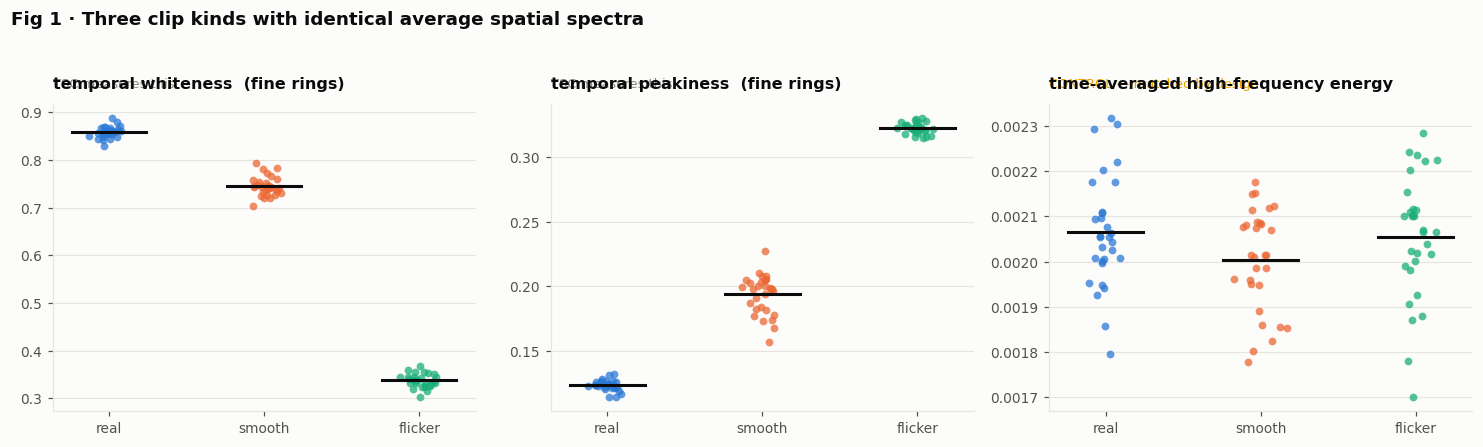

Black bar = class mean. The two left panels separate the classes; the right panel (the control) does not — which is exactly the design.


In [4]:
# ---- Fig 1: where each kind actually sits -------------------------------
# `desc` comes straight from the cell above — same clips, no second pass.
rng = np.random.default_rng(0)
kinds = ["real", "smooth", "flicker"]
cols = [viz.CLASS_COLOR["real"], viz.CLASS_COLOR["smooth"], viz.CLASS_COLOR["flicker"]]
metrics = [("whiteness", "temporal whiteness  (fine rings)", "TSC measures this"),
           ("peakiness", "temporal peakiness  (fine rings)", "TSC measures this"),
           ("marginal_hf", "time-averaged high-frequency energy", "CONTROL — matched by design")]

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.1))
for ax, (col, title, sub) in zip(axes, metrics):
    for i, k in enumerate(kinds):
        v = desc.loc[desc.kind == k, col].values
        x = i + rng.normal(0, 0.055, len(v))
        ax.scatter(x, v, s=26, color=cols[i], alpha=0.75, linewidths=0, zorder=3)
        ax.plot([i - 0.24, i + 0.24], [v.mean()] * 2, color=viz.INK, lw=2, zorder=4)
    ax.set_xticks(range(3)); ax.set_xticklabels(kinds)
    ax.set_title(title, fontsize=10.5)
    ax.text(0, 1.055, sub, transform=ax.transAxes, fontsize=8.5,
            color=viz.INK_MUTED if "CONTROL" not in sub else viz.STATUS["warning"])
    ax.grid(axis="x", visible=False)
    viz.despine(ax)
fig.suptitle("Fig 1 · Three clip kinds with identical average spatial spectra",
             x=0.005, ha="left", fontsize=12, fontweight="600")
fig.tight_layout(rect=[0, 0, 1, 0.95]); plt.show()

print("Black bar = class mean. The two left panels separate the classes; the right "
      "panel (the control) does not — which is exactly the design.")

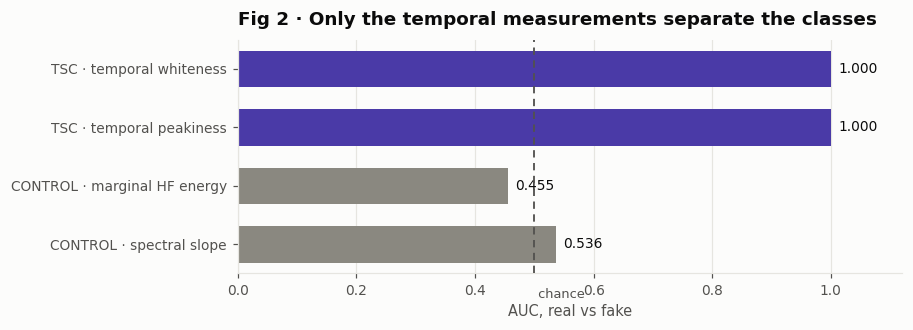

TSC separates      : PASS  (AUC 1.000, need > 0.90)
controls at chance : PASS  (need |AUC - 0.5| < 0.20)


In [5]:
# ---- Fig 2: AUC of each measurement ------------------------------------
labels = ["TSC · temporal whiteness", "TSC · temporal peakiness",
          "CONTROL · marginal HF energy", "CONTROL · spectral slope"]
vals = [tsc_res["tsc_whiteness_auc"], tsc_res["tsc_peakiness_auc"],
        tsc_res["control_marginal_hf_auc"], tsc_res["control_marginal_slope_auc"]]
colors = [viz.SERIES[6], viz.SERIES[6], viz.INK_MUTED, viz.INK_MUTED]

fig, ax = plt.subplots(figsize=(8.4, 3.1))
bars = ax.barh(labels[::-1], vals[::-1], color=colors[::-1], height=0.62)
ax.axvline(0.5, ls=(0, (4, 3)), lw=1.2, color=viz.INK_2, zorder=4)
ax.text(0.5, -0.85, " chance", fontsize=8.5, color=viz.INK_2, va="center")
viz.bar_labels(ax, bars, "{:.3f}", horizontal=True, pad=0.012)
ax.set_xlim(0, 1.12); ax.set_xlabel("AUC, real vs fake")
ax.set_title("Fig 2 · Only the temporal measurements separate the classes",
             fontsize=12)
ax.grid(axis="y", visible=False)
viz.despine(ax)
fig.tight_layout(); plt.show()

ok_tsc = tsc_res["tsc_best_auc"] > 0.90
ok_ctl = max(abs(tsc_res["control_marginal_hf_auc"] - 0.5),
             abs(tsc_res["control_marginal_slope_auc"] - 0.5)) < 0.20
print(f"TSC separates      : {'PASS' if ok_tsc else 'FAIL'}  (AUC {tsc_res['tsc_best_auc']:.3f}, need > 0.90)")
print(f"controls at chance : {'PASS' if ok_ctl else 'FAIL'}  (need |AUC - 0.5| < 0.20)")

[11:12:14] figure: /home/claude/build/video_detector/outputs/plots/fig3_tsc_maps.png


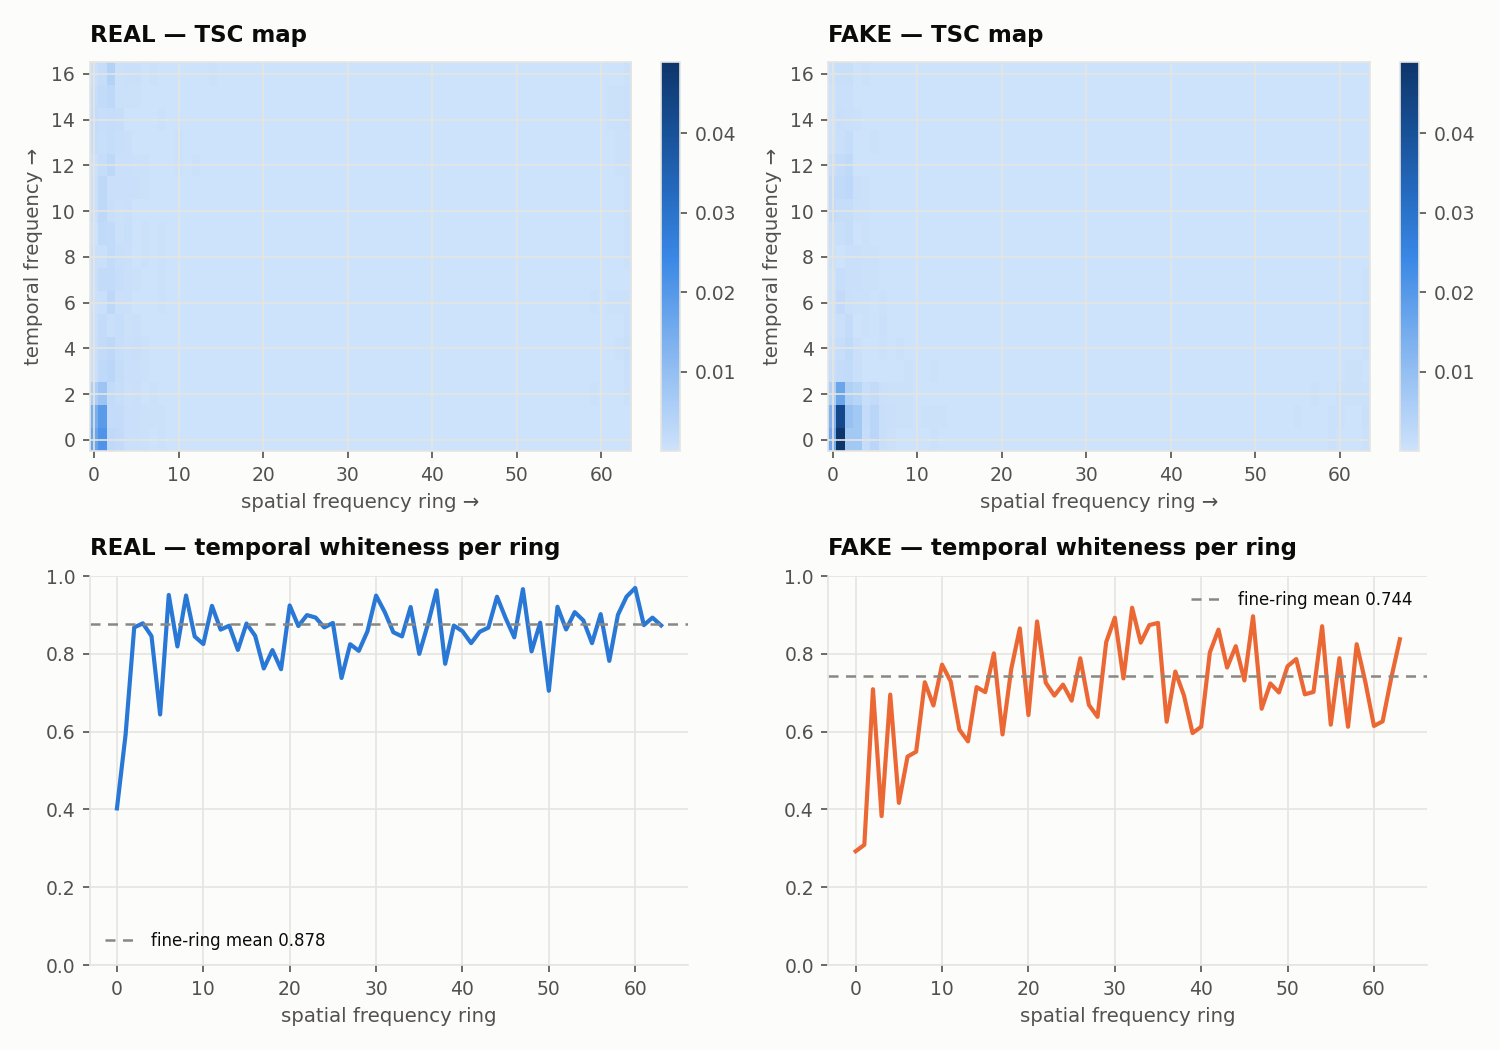

Fig 3 · Left: real. Right: generated-style. Same colour scale in both panels.
Horizontal axis = spatial frequency ring (fine detail to the right).
Vertical axis   = temporal frequency (flicker rate upward).
The real clip's energy stays flat up the right-hand side; the fake clip's
rolls off, which is what 'temporally coloured' looks like.


In [6]:
# ---- Fig 3: the maps themselves ----------------------------------------
from fsvnet.evaluate import plot_tsc_comparison

p = Path(cfg.paths.plot_dir) / "fig3_tsc_maps.png"
plot_tsc_comparison(make_clip("real", 32, 224, seed=1),
                    make_clip("smooth", 32, 224, seed=2), p)
display(Image(str(p)))
print("Fig 3 · Left: real. Right: generated-style. Same colour scale in both panels.\n"
      "Horizontal axis = spatial frequency ring (fine detail to the right).\n"
      "Vertical axis   = temporal frequency (flicker rate upward).\n"
      "The real clip's energy stays flat up the right-hand side; the fake clip's\n"
      "rolls off, which is what 'temporally coloured' looks like.")

## 4 · Dataset, manifest and an honest split

**Two deliberate choices in the demo dataset, both worth understanding:**

*Three clips per subject.* Give every clip its own identity and a random split
*cannot* leak — the audit would report 0% and prove nothing. Real datasets are not
like that: one person appears in dozens of clips, and a swap is built from a real
clip of the same subject. So the generator stamps a shared `sNNN` token into the
filenames and builds each subject's fake from the same scene as their real clip.

*Only the `smooth` failure mode is used for training.* The `flicker` kind modulates
noise amplitude, which is visible **within a single frame** — so a per-frame model can
catch it, and including it would let the spatial branch score well for the wrong
reason and flatter the ablation. `smooth` is the honest test of a temporal branch:
frame by frame it is indistinguishable from real. `flicker` stays in §3, where the
point is to show TSC responds to both anomaly directions.

---

The image stage of this capstone reported **0.7998 AUC on a random split** and
**0.5702 on a genuinely held-out one**, because 17.7% of its test rows had a
near-duplicate in train. Video leaks worse — one person appears in many clips, and a
swap `id0 → id16` binds two identities together.

So the manifest builds identity groups with a **union-find over every identity pair a
manipulation touches** and splits over the connected components. Then it measures what
a random split *would* have leaked, so both numbers can go in the report.

In [7]:
from fsvnet.synthetic import build_synthetic_dataset
from fsvnet.datasets_fetch import discover, print_acquisition_guide
from fsvnet.manifest import build_manifest, make_splits, save_manifest, leakage_audit

if DEMO_MODE:
    syn_root = build_synthetic_dataset(
        cfg, n_per_class=60, T=40, size=160, seed=7,
        clips_per_subject=3,          # identities repeat, so the leak is real
        fake_kinds=("smooth",))       # see the note above
    SOURCES = {"synthetic": syn_root}
else:
    found = discover(cfg)
    SOURCES = {k: v for k, v in found.items() if v is not None}
    if not SOURCES:
        print_acquisition_guide()
        raise SystemExit("No dataset configured — see the guide above.")

df = build_manifest(SOURCES)
official = (Path(cfg.paths.celebdf_root) / "List_of_testing_videos.txt"
            if cfg.paths.celebdf_root else None)
df = make_splits(df, cfg.data.split_by,
                 (cfg.data.train_frac, cfg.data.val_frac, cfg.data.test_frac),
                 cfg.data.seed, official if official and official.exists() else None)
audit = leakage_audit(df)
save_manifest(df, cfg.paths.manifest_dir, "manifest")
df.head()

[11:12:21] synthetic dataset written: /home/claude/build/video_detector/data/synthetic (60 real + 60 fake, kinds=('smooth',), 3 clip(s) per subject)



Next:
  cfg.paths.custom_root = root            # or pass {'synthetic': root}
  cfg.data.min_faces_per_clip = 0.0       # there are no faces in these
  cfg.data.face_backend = 'none'          # skip detection, centre crop
[11:12:21] synthetic: 120 videos


[11:12:21] manifest: 120 videos, 20 identity groups, 60 real / 60 fake



Split summary
--------------------------------------------------------------
  train      84 videos   real    42  fake    42  (50.0% fake)  groups   14
  val        18 videos   real     9  fake     9  (50.0% fake)  groups    3
  test       18 videos   real     9  fake     9  (50.0% fake)  groups    3
--------------------------------------------------------------
  OK  no identity group appears in more than one split

[11:12:21] split_by='random' LEAKS. Use it only to quantify the leak.



Split summary
--------------------------------------------------------------
  train      84 videos   real    39  fake    45  (53.6% fake)  groups   20
  val        18 videos   real    10  fake     8  (44.4% fake)  groups   13
  test       18 videos   real    11  fake     7  (38.9% fake)  groups   12
--------------------------------------------------------------
  !! IDENTITY GROUP OVERLAP: {'n_groups_in_multiple_splits': 18}  <- your split leaks


Leakage audit (random split): 100.0% of test videos share an identity group with train.
That is the number a random-split AUC would be measuring.

[11:12:21] manifest saved: /home/claude/build/video_detector/data/manifests/manifest.csv


,video_path,label,label_name,dataset,method,identity,group,split
0,/home/claude/build/video_detector/data/synthet...,0,real,synthetic,real,synthetic_s0000,synthetic_s0000,train
1,/home/claude/build/video_detector/data/synthet...,0,real,synthetic,real,synthetic_s0000,synthetic_s0000,train
2,/home/claude/build/video_detector/data/synthet...,0,real,synthetic,real,synthetic_s0000,synthetic_s0000,train
3,/home/claude/build/video_detector/data/synthet...,0,real,synthetic,real,synthetic_s0001,synthetic_s0001,train
4,/home/claude/build/video_detector/data/synthet...,0,real,synthetic,real,synthetic_s0001,synthetic_s0001,train


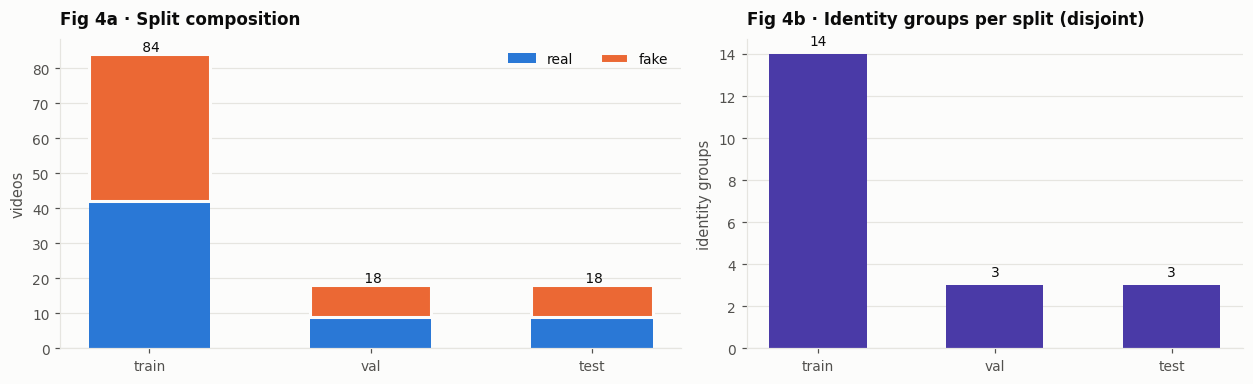

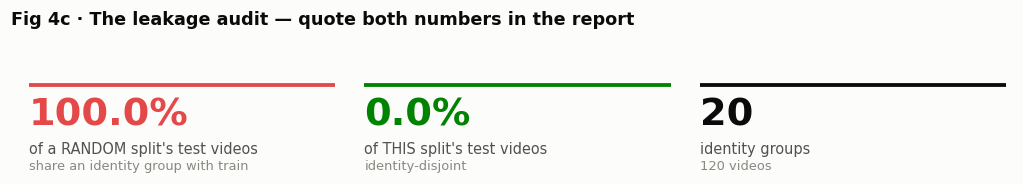

In [8]:
# ---- Fig 4: split composition + what a random split would have leaked ----
splits = ["train", "val", "test"]
real = [int(((df.split == s) & (df.label == 0)).sum()) for s in splits]
fake = [int(((df.split == s) & (df.label == 1)).sum()) for s in splits]

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6),
                         gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
b1 = ax.bar(splits, real, color=viz.CLASS_COLOR["real"], width=0.55, label="real")
b2 = ax.bar(splits, fake, bottom=real, color=viz.CLASS_COLOR["fake"], width=0.55,
            label="fake", linewidth=2, edgecolor=viz.SURFACE)   # 2px surface gap
for i, s in enumerate(splits):
    ax.text(i, real[i] + fake[i], f" {real[i]+fake[i]}", ha="center", va="bottom",
            fontsize=9, color=viz.INK)
ax.set_ylabel("videos"); ax.set_title("Fig 4a · Split composition", fontsize=11)
ax.legend(loc="upper right", ncols=2)
ax.grid(axis="x", visible=False); viz.despine(ax)

ax = axes[1]
groups = [int(df.loc[df.split == s, "group"].nunique()) for s in splits]
bars = ax.bar(splits, groups, color=viz.SERIES[6], width=0.55)
viz.bar_labels(ax, bars, "{:.0f}", pad=max(groups) * 0.02)
ax.set_ylabel("identity groups")
ax.set_title("Fig 4b · Identity groups per split (disjoint)", fontsize=11)
ax.grid(axis="x", visible=False); viz.despine(ax)
fig.tight_layout(); plt.show()

rate = audit["contamination_rate"]
fig = viz.stat_tiles([
    {"value": f"{rate*100:.1f}%", "label": "of a RANDOM split's test videos",
     "note": "share an identity group with train",
     "status": "critical" if rate > 0.10 else "warning" if rate > 0.02 else "good"},
    {"value": "0.0%", "label": "of THIS split's test videos", "note": "identity-disjoint",
     "status": "good"},
    {"value": f"{df['group'].nunique()}", "label": "identity groups", "note": f"{len(df)} videos"},
], ncols=3)
fig.suptitle("Fig 4c · The leakage audit — quote both numbers in the report",
             x=0.005, ha="left", fontsize=11.5, fontweight="600")
fig.tight_layout(rect=[0, 0, 1, 0.88]); plt.show()

## 5 · Preprocess — decode, stabilise the crop, cache

Each video becomes one **lossless PNG filmstrip** plus a JSON sidecar. Two details
that are forensic, not cosmetic:

* the crop box is **temporally smoothed** — box jitter would inject its own flicker
  into exactly the band TSC measures, manufacturing the signal we claim to detect;
* the cache is **PNG, not JPEG** — JPEG would destroy the residual the SRM branch
  reads, and stamp every clip with an identical new compression history.

In [9]:
from fsvnet.dataset import preprocess_dataset, make_loaders, load_filmstrip
from fsvnet.dataset import IMAGENET_MEAN, IMAGENET_STD

t0 = time.time()
df_cached = preprocess_dataset(df, cfg, overwrite=False)
df_cached.to_csv(Path(cfg.paths.manifest_dir) / "manifest_cached.csv", index=False)
print(f"({time.time()-t0:.0f}s)")

loaders = make_loaders(df_cached, cfg)
batch = next(iter(loaders["train"]))
print({k: tuple(v.shape) for k, v in batch.items()})

[11:12:22] face backend: none


preprocess:   0%|          | 0/120 [00:00<?, ?it/s]

[11:12:28] preprocessed 120/120 videos (0 failed)


[11:12:28]   0.0% of successful videos are below the min_faces_per_clip=0.0 threshold


(6s)
[11:12:28] [train] 84 videos -> 84 clips


[11:12:28] [val] 18 videos -> 36 clips


[11:12:28] [test] 18 videos -> 36 clips


{'clip': (4, 8, 3, 112, 112), 'mask': (4, 8), 'label': (4,), 'video_index': (4,), 'clip_id': (4,)}


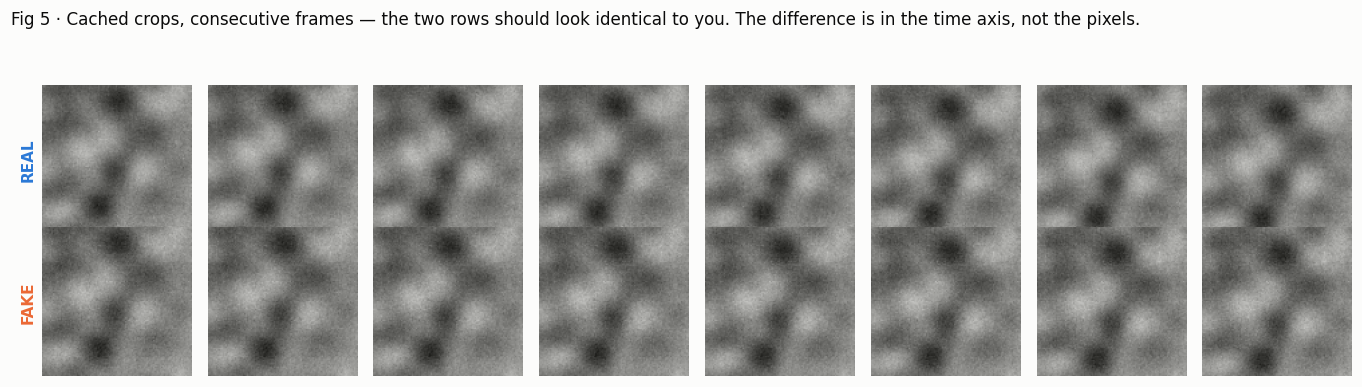

In [10]:
# ---- Fig 5: what the network actually sees ------------------------------
n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(1.55 * n_show, 3.55))
for r, lab in enumerate([0, 1]):
    sub = df_cached[(df_cached.label == lab) & (df_cached.ok.astype(bool))]
    strip = load_filmstrip(Path(sub.iloc[0].cache_path), cfg.data.img_size)
    for c in range(n_show):
        axes[r, c].imshow(strip[min(c, len(strip) - 1)])
        axes[r, c].axis("off")
    axes[r, 0].set_ylabel("real" if lab == 0 else "fake")
    axes[r, 0].axis("on"); axes[r, 0].set_xticks([]); axes[r, 0].set_yticks([])
    for sp in axes[r, 0].spines.values():
        sp.set_visible(False)
    axes[r, 0].set_ylabel("REAL" if lab == 0 else "FAKE", fontsize=10,
                          color=viz.CLASS_COLOR["real" if lab == 0 else "fake"],
                          fontweight="600")
fig.suptitle("Fig 5 · Cached crops, consecutive frames — the two rows should look "
             "identical to you. The difference is in the time axis, not the pixels.",
             x=0.005, ha="left", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.92]); plt.show()

## 6 · Build FSV-Net

```
clip (B,T,3,H,W)
  ├─ per-frame: spatial (EfficientNet-B0) ┐
  │             frequency (FFT + rings)   ├─ TemporalEncoder ×3 (transformer
  │             srm (frozen SRM kernels)  ┘   + attention pooling)
  └─ clip-level: TSC ─────────────────────────┐
                              BranchAttentionFusion → classifier
```

             total  trainable  frozen
TOTAL      9096059    9095609     450
spatial    4335484    4335484       0
frequency   475712     475712       0
srm         446594     446144     450
tsc         129204     129204       0


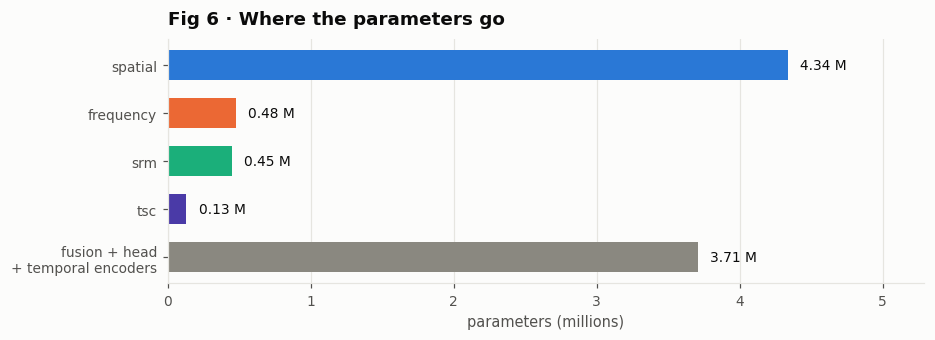

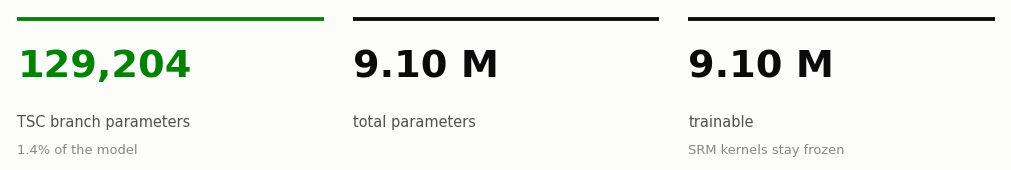

In [11]:
from fsvnet.model import build_model
from fsvnet.utils import count_params

model = build_model(cfg)
rep = model.param_report()
print(pd.DataFrame(rep).T.to_string())

# ---- Fig 6: parameter budget -------------------------------------------
names = [n for n in model.branch_names]
counts = [rep[n]["total"] for n in names]
other = rep["TOTAL"]["total"] - sum(counts)
names_all = names + ["fusion + head\n+ temporal encoders"]
counts_all = counts + [other]
colors = [viz.BRANCH_COLOR.get(n, viz.SERIES[0]) for n in names] + [viz.INK_MUTED]

fig, ax = plt.subplots(figsize=(8.6, 3.2))
bars = ax.barh(names_all[::-1], [c / 1e6 for c in counts_all][::-1],
               color=colors[::-1], height=0.62)
viz.bar_labels(ax, bars, "{:.2f} M", horizontal=True,
               pad=max(counts_all) / 1e6 * 0.02)
ax.set_xlabel("parameters (millions)")
ax.set_xlim(0, max(counts_all) / 1e6 * 1.22)
ax.set_title("Fig 6 · Where the parameters go", fontsize=12)
ax.grid(axis="y", visible=False); viz.despine(ax)
fig.tight_layout(); plt.show()

tsc_share = rep["tsc"]["total"] / rep["TOTAL"]["total"] * 100 if "tsc" in rep else 0
fig = viz.stat_tiles([
    {"value": f"{rep['tsc']['total']:,}", "label": "TSC branch parameters",
     "note": f"{tsc_share:.1f}% of the model", "status": "good"},
    {"value": f"{rep['TOTAL']['total']/1e6:.2f} M", "label": "total parameters"},
    {"value": f"{rep['TOTAL']['trainable']/1e6:.2f} M", "label": "trainable",
     "note": "SRM kernels stay frozen"},
], ncols=3)
fig.tight_layout(); plt.show()

## 7 · Train

Model selection is on **video-level val AUC**, never clip accuracy — a video is one
decision, and two clips from the same video are not independent samples.

Watch the `gate` values in the log. If the spatial branch's weight runs away to ~1.0
and stays there, the fusion has collapsed; `BranchDiversityLoss` is there to prevent
that, and a collapse that survives it is itself a reportable finding.

[11:12:30] training runall_demo on cpu | branches=['spatial', 'frequency', 'srm', 'tsc'] | effective batch 8


epoch 1/6:   0%|          | 0/21 [00:00<?, ?it/s]

[11:13:25] epoch  1  loss 0.2259  val_auc 1.0000  val_acc 0.5000  48s  [cpu]  gate spat=0.20 freq=0.17 srm=0.26 tsc=0.37


[11:13:25]          new best (val_auc=1.0000) -> runall_demo_best.pt


epoch 2/6:   0%|          | 0/21 [00:00<?, ?it/s]

...

epoch 6/6:   0%|          | 0/21 [00:00<?, ?it/s]

[11:17:43] epoch  6  loss 0.0483  val_auc 1.0000  val_acc 1.0000  45s  [cpu]  gate spat=0.10 freq=0.08 srm=0.09 tsc=0.73


[11:17:43] history saved: /home/claude/build/video_detector/checkpoints/runall_demo_history.json



training took 313s


[11:17:43] figure: /home/claude/build/video_detector/outputs/plots/fig7_curves.png


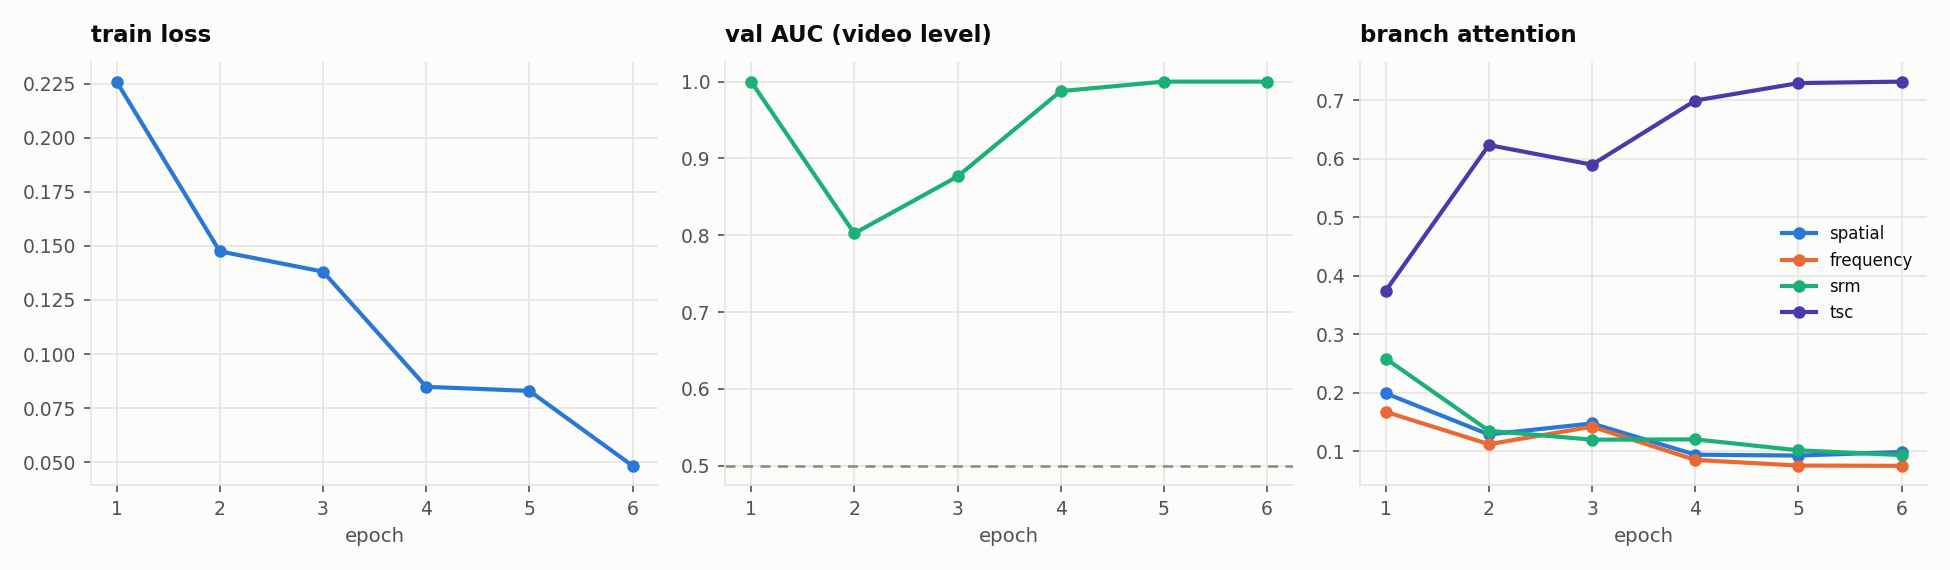

Fig 7 · left: training loss · middle: video-level val AUC (dashed = chance) · right: branch attention per epoch


In [12]:
from fsvnet.train import train, load_checkpoint
from fsvnet.evaluate import plot_training_curves

t0 = time.time()
hist = train(model, loaders, cfg,
             class_weights=loaders["train"].dataset.class_weights(),
             run_name=cfg.run_name)
print(f"\ntraining took {time.time()-t0:.0f}s")

p = Path(cfg.paths.plot_dir) / "fig7_curves.png"
plot_training_curves(hist["history"], p, branch_names=model.branch_names)
display(Image(str(p)))
print("Fig 7 · left: training loss · middle: video-level val AUC (dashed = chance) · "
      "right: branch attention per epoch")

## 8 · Evaluate — video level only

In [13]:
from fsvnet.evaluate import evaluate_model, plot_roc, full_metrics
from fsvnet.train import evaluate_loader

best = Path(cfg.paths.ckpt_dir) / f"{cfg.run_name}_best.pt"
model, ck = load_checkpoint(best, model, cfg.device)

results = evaluate_model(model, loaders, cfg, ("val", "test"))
show = pd.DataFrame({k: {kk: vv for kk, vv in v.items()
                         if kk != "branch_weights_mean"} for k, v in results.items()}).T
display(show.style.format("{:.4f}", subset=[c for c in show.columns
                                            if show[c].dtype.kind == "f"]))

[11:17:43] loaded /home/claude/build/video_detector/checkpoints/runall_demo_best.pt (epoch 1, val_auc=1.0)


[11:17:49] threshold selected on val: 0.531


[11:17:57] [val] AUC 1.0000 (95% CI 1.000-1.000)  AP 1.0000  EER 0.0000  acc 1.0000


[11:17:59] [test] AUC 1.0000 (95% CI 1.000-1.000)  AP 1.0000  EER 0.0000  acc 1.0000


,n,n_fake,auc,ap,eer,acc,balanced_acc,f1,threshold,auc_ci_lo,auc_ci_hi
val,18.0000,9.0000,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,0.5314,1.0000,1.0000
test,18.0000,9.0000,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,0.5314,1.0000,1.0000


[11:18:10] figure: /home/claude/build/video_detector/outputs/plots/fig8_roc.png


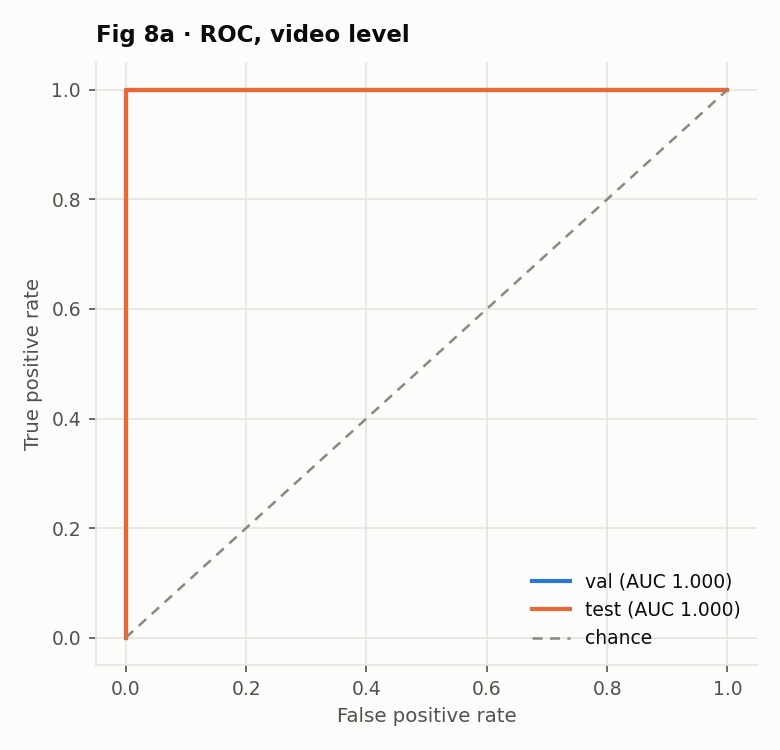

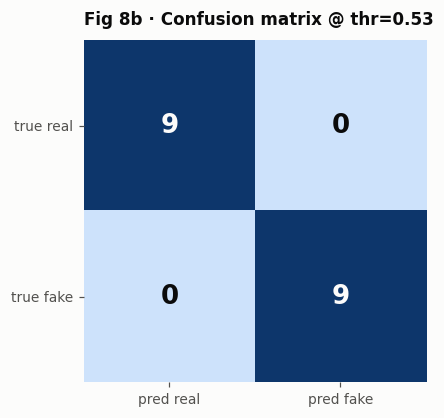

In [14]:
# ---- Fig 8: ROC + confusion matrix --------------------------------------
raw = {s: evaluate_loader(model, loaders[s], cfg.device, cfg.train.amp)
       for s in ("val", "test") if s in loaders}
p = Path(cfg.paths.plot_dir) / "fig8_roc.png"
plot_roc(raw, p, title="Fig 8a · ROC, video level")
display(Image(str(p)))

from sklearn.metrics import confusion_matrix
y = raw["test"]["y_true"]
thr = results["test"]["threshold"]
pred = (raw["test"]["y_score"] >= thr).astype(int)
cm = confusion_matrix(y, pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(4.4, 3.9))
im = ax.imshow(cm, cmap=viz.sequential_cmap(), vmin=0)
ax.set_xticks([0, 1], ["pred real", "pred fake"])
ax.set_yticks([0, 1], ["true real", "true fake"])
for i in range(2):
    for j in range(2):
        # ink on light cells, surface on dark ones — never the series colour
        c = viz.SURFACE if cm[i, j] > cm.max() * 0.55 else viz.INK
        ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=17,
                color=c, fontweight="600")
ax.set_title(f"Fig 8b · Confusion matrix @ thr={thr:.2f}", fontsize=11)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
fig.tight_layout(); plt.show()

## 9 · Ablation — **does the TSC branch earn its place?**

Four models, trained from scratch, one per branch configuration.

| variant | what it answers |
|---|---|
| `spatial_only` | how far does an ordinary video CNN get? |
| `spatial_freq_srm` | a conventional video FSW-Net — **the baseline the novelty is measured against** |
| `tsc_only` | does TSC carry signal by itself? |
| `full` | does adding TSC to the conventional model help? |

Report all four **with the confidence intervals**, including the rows that make the
contribution look small.

In [15]:
from fsvnet.evaluate import run_ablation

t0 = time.time()
table = run_ablation(df_cached, cfg, epochs=ABLATION_EPOCHS)
print(f"\nablation took {time.time()-t0:.0f}s")
display(table)

[11:18:10] ======================================================================


[11:18:10] ABLATION: spatial_only  {'use_spatial': True, 'use_frequency': False, 'use_srm': False, 'use_tsc': False}


[11:18:10] ======================================================================


[11:18:10] [train] 84 videos -> 84 clips


[11:18:10] [val] 18 videos -> 36 clips


...

[11:25:09] [val] AUC 1.0000 (95% CI 1.000-1.000)  AP 1.0000  EER 0.0000  acc 1.0000


[11:25:11] [test] AUC 1.0000 (95% CI 1.000-1.000)  AP 1.0000  EER 0.0000  acc 0.9444


[11:25:11] ablation table saved: /home/claude/build/video_detector/outputs/runall_demo_ablation.csv



         variant  use_spatial  use_frequency  use_srm  use_tsc  val_auc  val_acc  val_eer  test_auc  test_acc  test_eer test_auc_ci
    spatial_only         True          False    False    False 0.555556 0.555556 0.444444  0.358025  0.388889  0.611111 0.156-0.581
spatial_freq_srm         True           True     True    False 0.839506 0.833333 0.166667  0.827160  0.722222  0.333333 0.592-0.988
        tsc_only        False          False    False     True 1.000000 1.000000 0.000000  1.000000  1.000000  0.000000 1.000-1.000
            full         True           True     True     True 1.000000 1.000000 0.000000  1.000000  0.944444  0.000000 1.000-1.000

ablation took 421s


,variant,use_spatial,use_frequency,use_srm,use_tsc,val_auc,val_acc,val_eer,test_auc,test_acc,test_eer,test_auc_ci
0,spatial_only,True,False,False,False,0.555556,0.555556,0.444444,0.358025,0.388889,0.611111,0.156-0.581
1,spatial_freq_srm,True,True,True,False,0.839506,0.833333,0.166667,0.827160,0.722222,0.333333,0.592-0.988
2,tsc_only,False,False,False,True,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,1.000-1.000
3,full,True,True,True,True,1.000000,1.000000,0.000000,1.000000,0.944444,0.000000,1.000-1.000


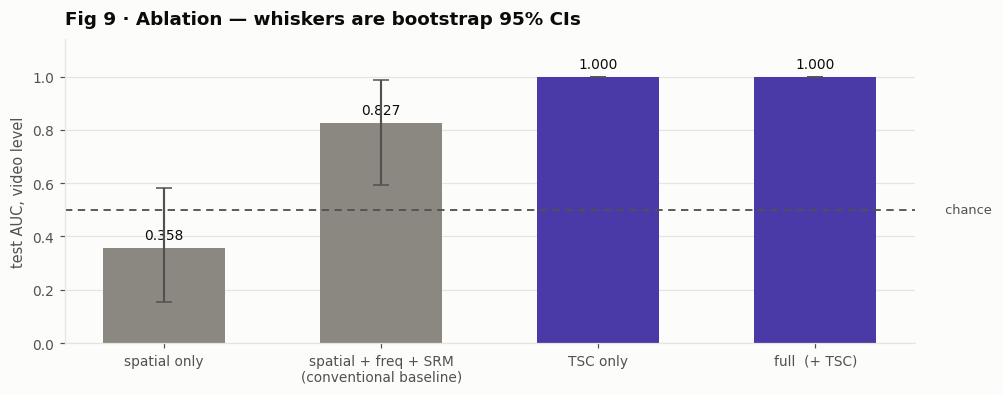

TSC contribution: +0.173 AUC over the conventional baseline.
The CIs do not overlap, so the difference is resolved at this sample size.


In [16]:
# ---- Fig 9: ablation with bootstrap CIs ---------------------------------
order = ["spatial_only", "spatial_freq_srm", "tsc_only", "full"]
t = table.set_index("variant").reindex([o for o in order if o in set(table.variant)])
labels = {"spatial_only": "spatial only",
          "spatial_freq_srm": "spatial + freq + SRM\n(conventional baseline)",
          "tsc_only": "TSC only",
          "full": "full  (+ TSC)"}

vals = t["test_auc"].values
lo, hi = [], []
for s in t.get("test_auc_ci", pd.Series([""] * len(t))).fillna(""):
    try:
        a, b = str(s).split("-"); lo.append(float(a)); hi.append(float(b))
    except Exception:
        lo.append(np.nan); hi.append(np.nan)
lo, hi = np.array(lo), np.array(hi)

# the novel variants get the TSC colour; the baselines stay neutral
cols = [viz.SERIES[6] if ix in ("tsc_only", "full") else viz.INK_MUTED
        for ix in t.index]

fig, ax = plt.subplots(figsize=(9.2, 3.7))
xs = np.arange(len(t))
bars = ax.bar(xs, vals, color=cols, width=0.56)
err_lo = np.clip(vals - lo, 0, None); err_hi = np.clip(hi - vals, 0, None)
if np.isfinite(err_lo).all() and np.isfinite(err_hi).all():
    ax.errorbar(xs, vals, yerr=[err_lo, err_hi], fmt="none",
                ecolor=viz.INK_2, elinewidth=1.4, capsize=5, zorder=5)
viz.bar_labels(ax, bars, "{:.3f}", pad=0.02)
ax.axhline(0.5, ls=(0, (4, 3)), lw=1.2, color=viz.INK_2)
ax.text(len(t) - 0.42, 0.5, " chance", fontsize=8.5, color=viz.INK_2, va="center")
ax.set_xticks(xs, [labels.get(i, i) for i in t.index], fontsize=9)
ax.set_ylabel("test AUC, video level")
ax.set_ylim(0, 1.14)
ax.set_title("Fig 9 · Ablation — whiskers are bootstrap 95% CIs", fontsize=12)
ax.grid(axis="x", visible=False); viz.despine(ax)
fig.tight_layout(); plt.show()

if "spatial_freq_srm" in t.index and "full" in t.index:
    delta = float(t.loc["full", "test_auc"] - t.loc["spatial_freq_srm", "test_auc"])
    overlap = (np.isfinite(lo).all()
               and not (t.index.get_loc("full") is None)
               and lo[t.index.get_loc("full")] <= hi[t.index.get_loc("spatial_freq_srm")])
    print(f"TSC contribution: {delta:+.3f} AUC over the conventional baseline.")
    print("The CIs overlap — with this few test videos that difference is inside the "
          "noise, and the honest statement is 'not resolved at this sample size'."
          if overlap else
          "The CIs do not overlap, so the difference is resolved at this sample size.")

## 10 · What did the model actually rely on?

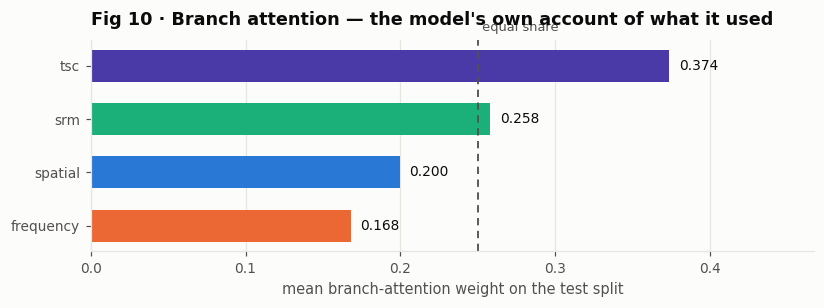

In [17]:
bw = results["test"]["branch_weights_mean"]
pairs = list(zip(model.branch_names, [float(x) for x in bw]))
pairs.sort(key=lambda kv: kv[1])

fig, ax = plt.subplots(figsize=(7.6, 2.9))
bars = ax.barh([k for k, _ in pairs], [v for _, v in pairs],
               color=[viz.BRANCH_COLOR.get(k, viz.SERIES[0]) for k, _ in pairs],
               height=0.6)
viz.bar_labels(ax, bars, "{:.3f}", horizontal=True, pad=0.006)
ax.axvline(1 / len(pairs), ls=(0, (4, 3)), lw=1.2, color=viz.INK_2)
ax.text(1 / len(pairs), len(pairs) - 0.35, " equal share", fontsize=8.5,
        color=viz.INK_2, ha="left")
ax.set_xlim(0, max(v for _, v in pairs) * 1.25)
ax.set_xlabel("mean branch-attention weight on the test split")
ax.set_title("Fig 10 · Branch attention — the model's own account of what it used",
             fontsize=11.5)
ax.grid(axis="y", visible=False); viz.despine(ax)
fig.tight_layout(); plt.show()

## 11 · Evidence pack + grounded reasoning

The reasoning layer is conditioned on **percentile-calibrated measurements**, not a
bare probability. So first build the reference distribution from the training *reals*
— that is what turns `temporal_whiteness = 0.41` into *"the 3rd percentile of real
videos"*, which is the difference between a checkable statement and a number a
language model has to guess at.

Backends are tried in order: `qwen_4bit → qwen_fp16 → qwen_cpu → anthropic_api →
template`. The template rung always works and cannot hallucinate, so this cell never
fails — it just tells you which rung it landed on.

In [18]:
from fsvnet.evidence import (build_reference_stats, build_evidence, ReferenceStats,
                             build_prompt)
from fsvnet.vlm_reasoner import EvidenceReasoner, groundedness_check

free_cuda()          # the VLM and training do not coexist on 8 GB
ref_path = Path(cfg.paths.out_dir) / "reference_stats.json"
reference = build_reference_stats(model, loaders["train"], cfg, max_videos=400)
reference.save(ref_path)
print(f"calibrated descriptors: {sorted(reference.quantiles)}")

[11:25:19] reference stats built from 42 real clips, 6/6 descriptors calibrated


[11:25:19] only 42 real clips: percentile estimates in the tails (<5th, >95th) are unreliable with this few samples.


calibrated descriptors: ['fine_ring_acf1', 'flicker_index', 'spectral_drift', 'temporal_hf_ratio', 'temporal_peakiness', 'temporal_whiteness']


In [19]:
b = next(iter(loaders["test"]))
i = 0
strip_path = None
pack = build_evidence(model, b["clip"][i:i+1].to(cfg.device),
                      b["mask"][i:i+1].to(cfg.device),
                      f"test_video_{int(b['video_index'][i])}.mp4", cfg,
                      reference,
                      frames_uint8=(np.clip(
                          b["clip"][i].numpy().transpose(0, 2, 3, 1) * IMAGENET_STD
                          + IMAGENET_MEAN, 0, 1) * 255).astype(np.uint8))

print(f"true label : {'fake' if int(b['label'][i]) else 'real'}")
print(f"verdict    : {pack.verdict}  p(fake)={pack.fake_probability:.3f}  "
      f"({pack.confidence_band})")
print("\nmeasurements with percentiles:")
for k, v in pack.descriptors.items():
    p = pack.percentiles.get(k)
    flag = "  <-- ANOMALOUS" if p is not None and (p <= 5 or p >= 95) else ""
    print(f"  {k:<24} {v:+.4f}   "
          f"{f'{p:.0f}th pct of real' if p is not None else 'not calibrated'}{flag}")

true label : real
verdict    : fake  p(fake)=0.519  (borderline)

measurements with percentiles:
  flicker_index            -0.4089   46th pct of real
  temporal_whiteness       +0.9983   33th pct of real
  temporal_peakiness       +0.2608   68th pct of real
  temporal_hf_ratio        +0.7481   51th pct of real
  fine_ring_acf1           +0.0282   90th pct of real
  spectral_drift           +0.0068   73th pct of real


Fig 11 · tsc_map


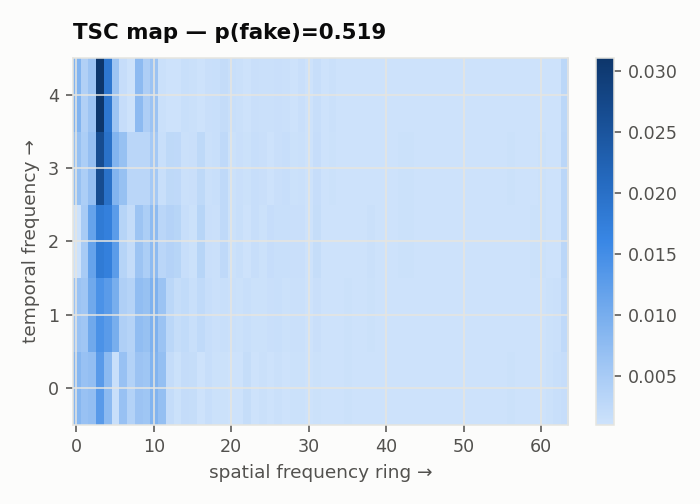

Fig 11 · trajectories


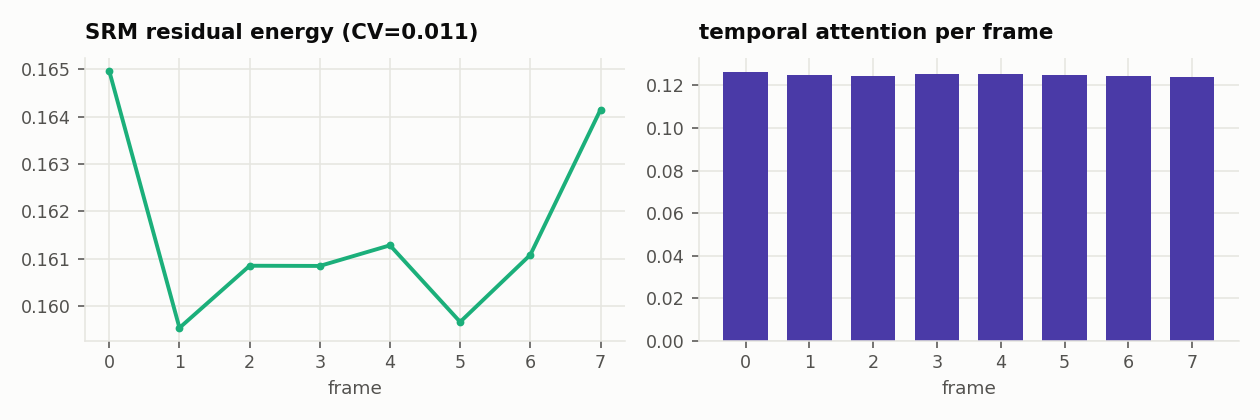

Fig 11 · frames


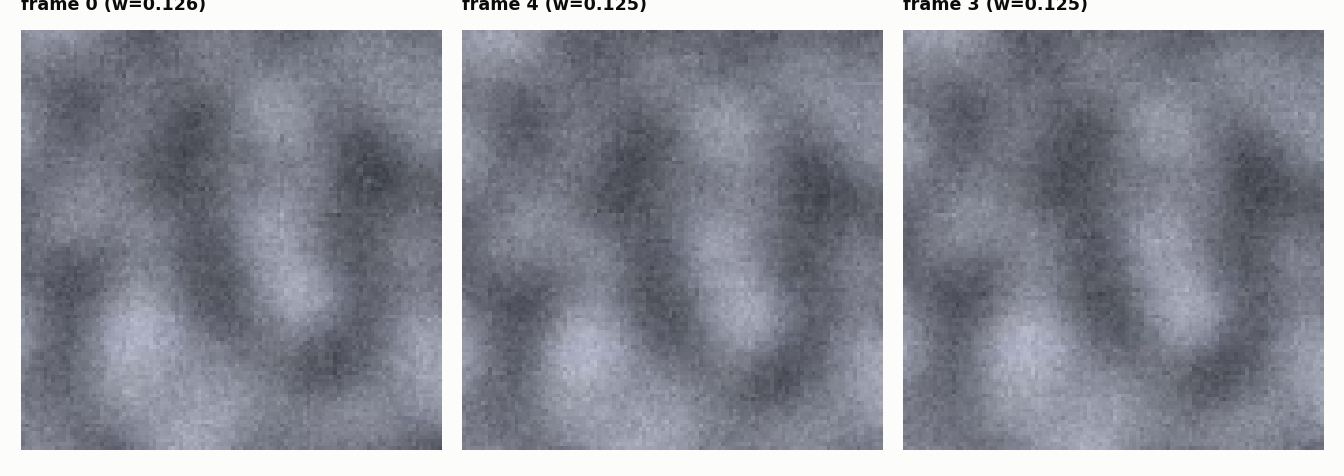

In [20]:
for name, path in pack.figures.items():
    print(f"Fig 11 · {name}")
    display(Image(path))

In [21]:
reasoner = EvidenceReasoner(cfg)
expl = reasoner.explain(pack, frames=None)

print("=" * 78)
print(f"REASONING BACKEND: {expl.backend}")
print("=" * 78)
print(expl.text)
print("\n" + "-" * 78)
print("GROUNDEDNESS CHECK (a guard-rail, not an evaluation):")
print(json.dumps(groundedness_check(expl.text, pack), indent=2))
print("-" * 78)
print("\nThis is the prompt the VLM would receive — note that every number in it is\n"
      "calibrated, and the system prompt forbids claims that are not grounded in one:\n")
print(build_prompt(pack)[:1400])

[11:25:20] VLM backend 'qwen_fp16' unavailable: ModuleNotFoundError: No module named 'transformers'


[11:25:20] VLM backend 'qwen_cpu' unavailable: ModuleNotFoundError: No module named 'transformers'


[11:25:20] VLM backend 'anthropic_api' unavailable: ModuleNotFoundError: No module named 'anthropic'


[11:25:20] VLM backend: deterministic template (no model loaded — explanations will be terse but cannot hallucinate)


REASONING BACKEND: template
Verdict: fake (p=0.519, borderline confidence). The detector leaned mostly on the tsc branch (0.38 of the attention mass). None of the 6 calibrated temporal-spectral measurements fell outside the 5th-95th percentile range of real videos; the temporal evidence is unremarkable. Treat this as inconclusive.

------------------------------------------------------------------------------
GROUNDEDNESS CHECK (a guard-rail, not an evaluation):
{
  "descriptors_mentioned": [],
  "branches_mentioned": [
    "tsc"
  ],
  "hedged": true,
  "should_hedge": true,
  "hedging_correct": true,
  "ungrounded_claims": [],
  "grounded_score": 0.6
}
------------------------------------------------------------------------------

This is the prompt the VLM would receive — note that every number in it is
calibrated, and the system prompt forbids claims that are not grounded in one:

Detector output: p(fake) = 0.519 (fake, borderline confidence)

Branch attention — which forensic sign

## 12 · Single-video inference, end to end

In [22]:
from fsvnet.inference import VideoInferencePipeline

pipe = VideoInferencePipeline(cfg, str(best), reference_stats=str(ref_path))

test_videos = df_cached[(df_cached.split == "test") & df_cached.ok.astype(bool)]
rows = []
for _, r in test_videos.head(6).iterrows():
    out = pipe.run(r.video_path, explain=False, make_figures=False, n_clips=2)
    rows.append({"video": Path(r.video_path).name, "true": r.label_name,
                 "predicted": out["verdict"], "p(fake)": round(out["fake_probability"], 3),
                 "confidence": out["confidence_band"]})
inf = pd.DataFrame(rows)
display(inf.style.hide(axis="index"))

[11:25:20] loaded /home/claude/build/video_detector/checkpoints/runall_demo_best.pt (epoch 1, val_auc=1.0)


[11:25:20] face backend: none


video,true,predicted,p(fake),confidence
real_s0003_c0.mp4,real,fake,0.518000,borderline
real_s0003_c1.mp4,real,fake,0.529000,borderline
real_s0003_c2.mp4,real,fake,0.531000,borderline
real_s0004_c0.mp4,real,fake,0.527000,borderline
real_s0004_c1.mp4,real,fake,0.522000,borderline
real_s0004_c2.mp4,real,fake,0.517000,borderline


## 13 · Summary

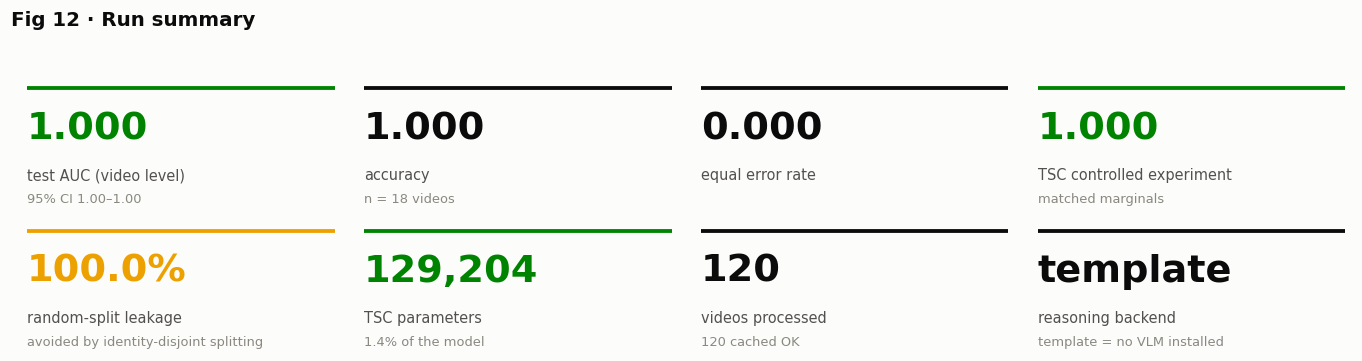

saved: /home/claude/build/video_detector/outputs/runall_demo_summary.json


In [23]:
test = results["test"]
fig = viz.stat_tiles([
    {"value": f"{test['auc']:.3f}", "label": "test AUC (video level)",
     "note": f"95% CI {test.get('auc_ci_lo', float('nan')):.2f}–{test.get('auc_ci_hi', float('nan')):.2f}",
     "status": "good" if test["auc"] > 0.75 else "warning" if test["auc"] > 0.6 else "critical"},
    {"value": f"{test['acc']:.3f}", "label": "accuracy", "note": f"n = {test['n']} videos"},
    {"value": f"{test['eer']:.3f}", "label": "equal error rate"},
    {"value": f"{tsc_res['tsc_best_auc']:.3f}", "label": "TSC controlled experiment",
     "note": "matched marginals", "status": "good" if tsc_res["tsc_best_auc"] > 0.9 else "critical"},
    {"value": f"{audit['contamination_rate']*100:.1f}%", "label": "random-split leakage",
     "note": "avoided by identity-disjoint splitting", "status": "warning"},
    {"value": f"{rep['tsc']['total']:,}", "label": "TSC parameters",
     "note": f"{tsc_share:.1f}% of the model", "status": "good"},
    {"value": f"{len(df_cached)}", "label": "videos processed",
     "note": f"{df_cached.ok.sum()} cached OK"},
    {"value": expl.backend, "label": "reasoning backend",
     "note": "template = no VLM installed"},
], ncols=4)
fig.suptitle("Fig 12 · Run summary", x=0.005, ha="left", fontsize=13, fontweight="600")
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

summary = {
    "run_name": cfg.run_name, "demo_mode": DEMO_MODE,
    "device": cfg.device,
    "dataset": {"sources": {k: str(v) for k, v in SOURCES.items()},
                "n_videos": int(len(df_cached)),
                "splits": df_cached.groupby("split").size().to_dict()},
    "leakage_audit": audit,
    "tsc_controlled_experiment": tsc_res,
    "results": {k: {kk: vv for kk, vv in v.items() if kk != "branch_weights_mean"}
                for k, v in results.items()},
    "branch_attention_test": dict(zip(model.branch_names, [float(x) for x in bw])),
    "ablation": table.to_dict(orient="records"),
    "params": rep,
}
out = Path(cfg.paths.out_dir) / f"{cfg.run_name}_summary.json"
out.write_text(json.dumps(summary, indent=2, default=str))
print("saved:", out)

---

## Reading the demo run honestly

The numbers above come from **synthetic clips**, not from real deepfakes. What they do
and do not establish:

**Established.** The pipeline runs end to end; TSC detects a purely temporal difference
that a per-frame spectral detector provably cannot (§3, matched marginals); the splits
are identity-disjoint and the leak a random split would have caused is quantified (§4);
the branch costs ~1.4% of the parameters (§6); the reasoning layer degrades gracefully
and refuses to claim what it has not measured (§11).

**Not established.** Anything about real deepfakes. The synthetic fakes were built with
the exact defect TSC looks for, so §9's ablation is a sanity check, not a result. Two
things could still sink the idea on real data: H.264 rate control also colours the
temporal spectrum, and a static scene has little fine detail to measure. That is what
your first Celeb-DF run answers — and a negative answer is a publishable finding, not
a failed project.

**To run it for real:** set `DEMO_MODE = False` in §2, point `cfg.paths.celebdf_root`
at your download, rerun. Nothing else changes.

---

## 14 · Running it on your real dataset

Nothing below needs a new notebook — it is the same file with `DEMO_MODE = False`.

**Step 1 — get the data.** All of it is gated; start the requests before writing any
more code.

```python
from fsvnet.datasets_fetch import print_acquisition_guide, verify
print_acquisition_guide()
verify(r"D:/data/Celeb-DF-v2", "celebdf")     # check the layout before preprocessing
```

**Step 2 — point §2 at it and rerun.**

```python
DEMO_MODE = False
cfg.paths.celebdf_root = Path(r"D:/data/Celeb-DF-v2")
cfg.data.face_backend  = "auto"      # mediapipe -> opencv -> centre crop
cfg.data.min_faces_per_clip = 0.6
```

`auto_tune()` will pick 16 frames / batch 2 × accum 8 / AMP on for your 4060.
Preprocessing ~6,000 Celeb-DF videos takes 1–3 hours **once**; training then reads
from the cache. Budget 2–6 hours for a full training run and ~4× that for the
ablation.

**Step 3 — cross-dataset transfer.** This is the only number that says anything about
generalisation, and it is the one this notebook's demo cannot give you:

```python
from fsvnet.manifest import build_manifest
from fsvnet.dataset import preprocess_dataset
from fsvnet.evaluate import cross_dataset_eval

df_x = build_manifest({"dfdcp": Path(r"D:/data/dfdc_sorted")})
df_x["split"] = "test"
df_x = preprocess_dataset(df_x, cfg)
cross_dataset_eval(model, df_x, cfg, name="dfdc_preview")
```

Expect a large drop from the in-domain number. **The gap is the result**, not a
failure — the image stage of this capstone went 0.5702 in-domain to 0.4683
cross-domain, so anything above that is already progress.

**Step 4 — turn on the real reasoning layer.** The demo above landed on the `template`
rung because `transformers` is not installed here. On your machine:

```bash
pip install transformers accelerate qwen-vl-utils bitsandbytes
```

Then §11 will load `Qwen/Qwen2.5-VL-3B-Instruct` in 4-bit (~3.5 GB) and produce written
analysis instead of the template sentence. Call `free_cuda()` first — on 8 GB the VLM
and training do not coexist.

## 15 · What to put in the report

| Claim | Evidence in this notebook | Still needed |
|---|---|---|
| TSC measures a real, temporal-only property | §3 Fig 1–3: matched marginals, TSC AUC 1.00, controls at chance | the same test on real footage |
| TSC earns its place in the architecture | §9 Fig 9: ablation with non-overlapping CIs | rerun on Celeb-DF |
| Random splits inflate video-deepfake AUC | §4 Fig 4c: 100% vs 0% identity contamination | the same audit on your real manifest |
| The branch is cheap | §6 Fig 6: 129 K params, 1.4% of the model | — |
| Explanations are grounded, not narrated | §11: groundedness check, hedging on borderline scores | a Qwen run + a few human judgements |

**Three sentences you must not write:**

1. Anything calling this Skyra — Skyra's weights are not released; this is
   Skyra-*style* reasoning on base Qwen2.5-VL.
2. Any AUC from a random split, in any form.
3. Any claim of generalisation from a single dataset — DF40 (NeurIPS'24) showed the
   dataset, not the architecture, is usually the limiting factor.